In [40]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

(684, 428) (684, 428)


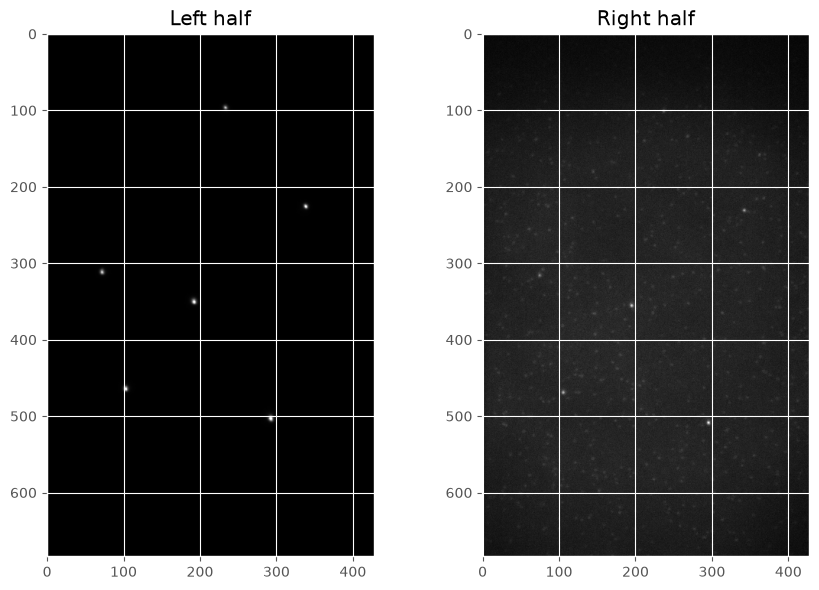

In [41]:
path = "low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif"

with Image.open(path) as image:
    image.seek(0)
    frame = np.array(image)

left = frame[:, :428]    # columns 0–427
right = frame[:, 428:]  # columns 428–855

print(left.shape, right.shape)  # both (684, 428)

fig, axes = plt.subplots(1, 2, figsize=(9, 6))
axes[0].imshow(left, cmap="gray")
axes[0].set_title("Left half")
axes[1].imshow(right, cmap="gray")
axes[1].set_title("Right half")

plt.tight_layout()
plt.show()

In [42]:
from picasso.localize import localize_frames

# Detection settings: starting values to explore, not calibrated thresholds.
params = {
    "Box Size": 7,
    "Min. Net Gradient": 3000,
}

# Placeholder camera conversion values for exploring spot positions.
# Replace these with your camera's calibration before interpreting photon counts.
camera_info = {
    "Baseline": 0,
    "Sensitivity": 1.0,
    "Gain": 1,
    "Pixelsize": 117,  # nm; your TIFF metadata says approximately 0.117 µm
}

left_locs = localize_frames(
    left[np.newaxis, :, :],  # Picasso expects (frames, height, width)
    info=None,
    params=params,
    camera_info=camera_info,
    fitting_method="gausslq",
    threaded=False,
)

right_locs = localize_frames(
    right[np.newaxis, :, :],
    info=None,
    params=params,
    camera_info=camera_info,
    fitting_method="gausslq",
    threaded=False,
)

print(f"Left: {len(left_locs)} localisations")
print(f"Right: {len(right_locs)} localisations")

left_locs.head()

Left: 20 localisations
Right: 78 localisations


,frame,x,y,photons,sx,sy,bg,lpx,lpy,ellipticity,net_gradient,iterations,chi_square
0,0,233.407318,96.389305,633680.125000,1.440142,1.511923,5571.129883,0.002784,0.002918,0.047476,914431.750000,3,1.455122e+08
17,0,74.841461,597.325317,1811.235474,1.219818,1.201481,405.454681,0.095406,0.094048,0.015033,3029.742676,4,8.667603e+03
16,0,383.234100,580.165527,1664.399780,1.075464,0.985090,412.829742,0.081443,0.075078,0.084033,3639.444092,3,5.918000e+03
15,0,254.683502,576.604248,1877.882080,1.046293,1.209313,408.803070,0.075809,0.086838,0.134804,3643.302979,3,7.810560e+03
14,0,156.555130,522.599548,1830.036621,1.302479,1.171235,408.080750,0.102471,0.092655,0.100765,3127.173584,3,7.628614e+03


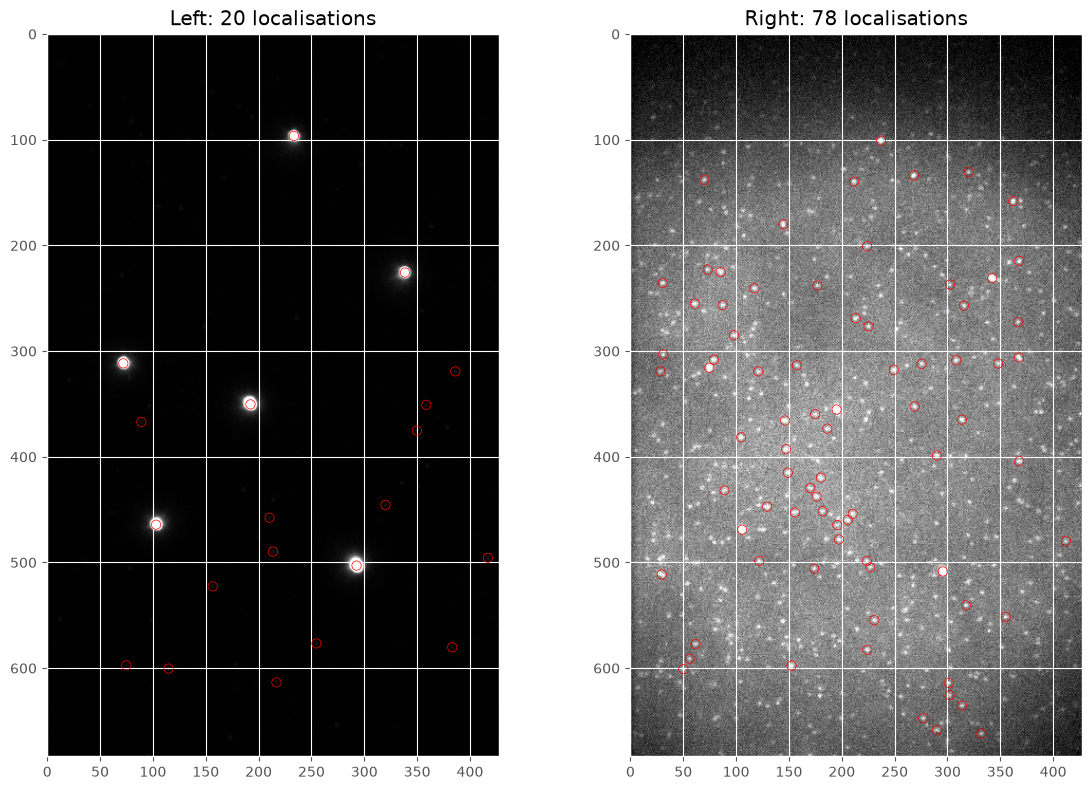

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

for ax, image_half, locs, title in zip(
    axes,
    [left, right],
    [left_locs, right_locs],
    ["Left", "Right"],
):
    vmin, vmax = np.percentile(image_half, [1, 99.8])
    ax.imshow(image_half, cmap="gray", vmin=vmin, vmax=vmax)

    ax.scatter(
        locs["x"], locs["y"],
        s=45, facecolors="none", edgecolors="red",
    )
    ax.set_title(f"{title}: {len(locs)} localisations")

plt.tight_layout()
plt.show()

In [44]:
import cv2
import numpy as np

# ------------------------------------------------------------
# 1. Extract the fitted (x, y) coordinates from each channel.
#
# Both sets of coordinates are relative to their own image half.
# The homography will map RIGHT-half coordinates -> LEFT-half
# coordinates.
# ------------------------------------------------------------

reference_points = left_locs[["x", "y"]].to_numpy(dtype=np.float32)
target_points = right_locs[["x", "y"]].to_numpy(dtype=np.float32)

if len(reference_points) == 0 or len(target_points) == 0:
    raise ValueError("Both channels need at least one localisation.")

# ------------------------------------------------------------
# 2. Find mutual nearest-neighbour matches.
#
# This is the same matching approach used by molSEEQ:
#   - NORM_L1 compares coordinates using Manhattan distance.
#   - crossCheck=True keeps a pair only when each point is the
#     other's nearest neighbour.
#
# Because reference_points is passed first:
#   match.queryIdx indexes reference_points
#   match.trainIdx indexes target_points
# ------------------------------------------------------------

matcher = cv2.BFMatcher(cv2.NORM_L1, crossCheck=True)

matches = matcher.match(reference_points, target_points)

# Sort the retained matches by their L1 distance.
# Sorting does not remove any matches.
matches = sorted(matches, key=lambda match: match.distance)

print(f"Found {len(matches)} mutual matches.")

if len(matches) < 4:
    raise ValueError(
        "At least four matched point pairs are needed for a homography."
    )

# Create corresponding arrays in the same order.
# Row i in matched_target corresponds to row i in matched_reference.
matched_reference = np.float32([
    reference_points[match.queryIdx] for match in matches
]) # pyright: ignore[reportArgumentType]

matched_target = np.float32([
    target_points[match.trainIdx] for match in matches
]) # pyright: ignore[reportArgumentType]

# ------------------------------------------------------------
# 3. Estimate the homography using RANSAC.
#
# The argument order sets the direction:
#
#     matched_target --H--> matched_reference
#
# This matches molSEEQ's call. It does not explicitly pass a
# reprojection threshold, so OpenCV uses its default.
# ------------------------------------------------------------

H, inlier_mask = cv2.findHomography(
    matched_target, # type: ignore
    matched_reference, # type: ignore
    cv2.RANSAC,
) # type: ignore

if H is None or inlier_mask is None:
    raise ValueError(
        "Homography estimation failed. Check the matches and whether "
        "the points are sufficiently well distributed."
    )

# Convert the returned 0/1 mask into a one-dimensional Boolean array.
inliers = inlier_mask.ravel().astype(bool)

print("Homography: right half -> left half")
print(H)
print(f"RANSAC inliers: {inliers.sum()} / {len(inliers)}")

Found 18 mutual matches.
Homography: right half -> left half
[[ 9.98412843e-01  1.77432232e-03 -3.17559570e+00]
 [-2.07112735e-03  9.97762041e-01 -3.54616251e+00]
 [ 6.08445039e-06 -2.33000983e-06  1.00000000e+00]]
RANSAC inliers: 6 / 18


In [45]:
# Transform each matched right-hand coordinate into the left-hand
# coordinate system. OpenCV expects shape (n_points, 1, 2).
predicted_reference = cv2.perspectiveTransform(
    matched_target.reshape(-1, 1, 2),
    H,
).reshape(-1, 2)

# Euclidean reprojection error in left-half pixels.
errors = np.linalg.norm(
    predicted_reference - matched_reference,
    axis=1,
)

for i, (error, is_inlier) in enumerate(zip(errors, inliers)):
    print(
        f"Match {i:3d}: "
        f"error = {error:7.3f} px  "
        f"{'inlier' if is_inlier else 'outlier'}"
    )

print(
    "\nMedian inlier error:",
    f"{np.median(errors[inliers]):.3f} px",
)

Match   0: error =   9.015 px  outlier
Match   1: error =   0.084 px  inlier
Match   2: error =   0.134 px  inlier
Match   3: error =   0.182 px  inlier
Match   4: error =   0.040 px  inlier
Match   5: error =   0.033 px  inlier
Match   6: error =   0.054 px  inlier
Match   7: error =   8.180 px  outlier
Match   8: error =  23.499 px  outlier
Match   9: error =  23.496 px  outlier
Match  10: error =  16.437 px  outlier
Match  11: error =  29.107 px  outlier
Match  12: error =  26.253 px  outlier
Match  13: error =  33.075 px  outlier
Match  14: error =  36.176 px  outlier
Match  15: error =  42.453 px  outlier
Match  16: error =  46.651 px  outlier
Match  17: error =  61.874 px  outlier

Median inlier error: 0.069 px


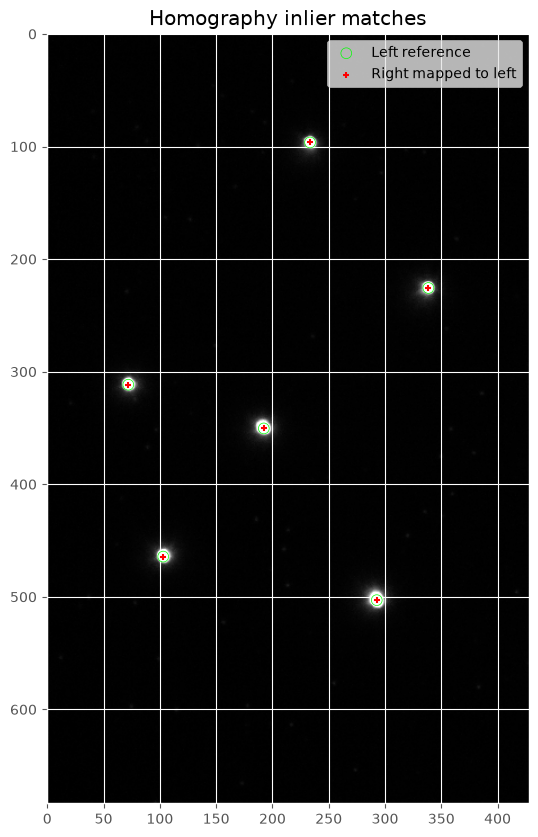

In [46]:
fig, ax = plt.subplots(figsize=(8, 10))

vmin, vmax = np.percentile(left, [1, 99.8])
ax.imshow(left, cmap="gray", vmin=vmin, vmax=vmax)

# Actual left-channel positions.
ax.scatter(
    matched_reference[inliers, 0], # type: ignore
    matched_reference[inliers, 1], # type: ignore
    s=60,
    facecolors="none",
    edgecolors="lime",
    label="Left reference",
)

# Right-channel positions after applying H.
ax.scatter(
    predicted_reference[inliers, 0],
    predicted_reference[inliers, 1],
    s=25,
    marker="+",
    c="red",
    label="Right mapped to left",
)

ax.set_title("Homography inlier matches")
ax.legend()
plt.show()

Localising 183 of 1826 frames...
  25/183 sampled frames
  50/183 sampled frames
  75/183 sampled frames
  100/183 sampled frames
  125/183 sampled frames
  150/183 sampled frames
  175/183 sampled frames
  183/183 sampled frames
Localisations per RCC segment: [495 290 272 345 232 284]


Correlating image pairs: 100%|██████████| 15/15 [00:00<00:00, 46.18pairs/s]


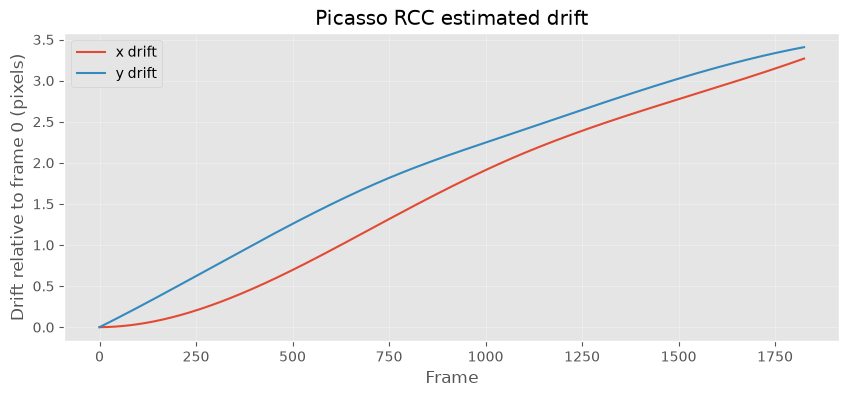

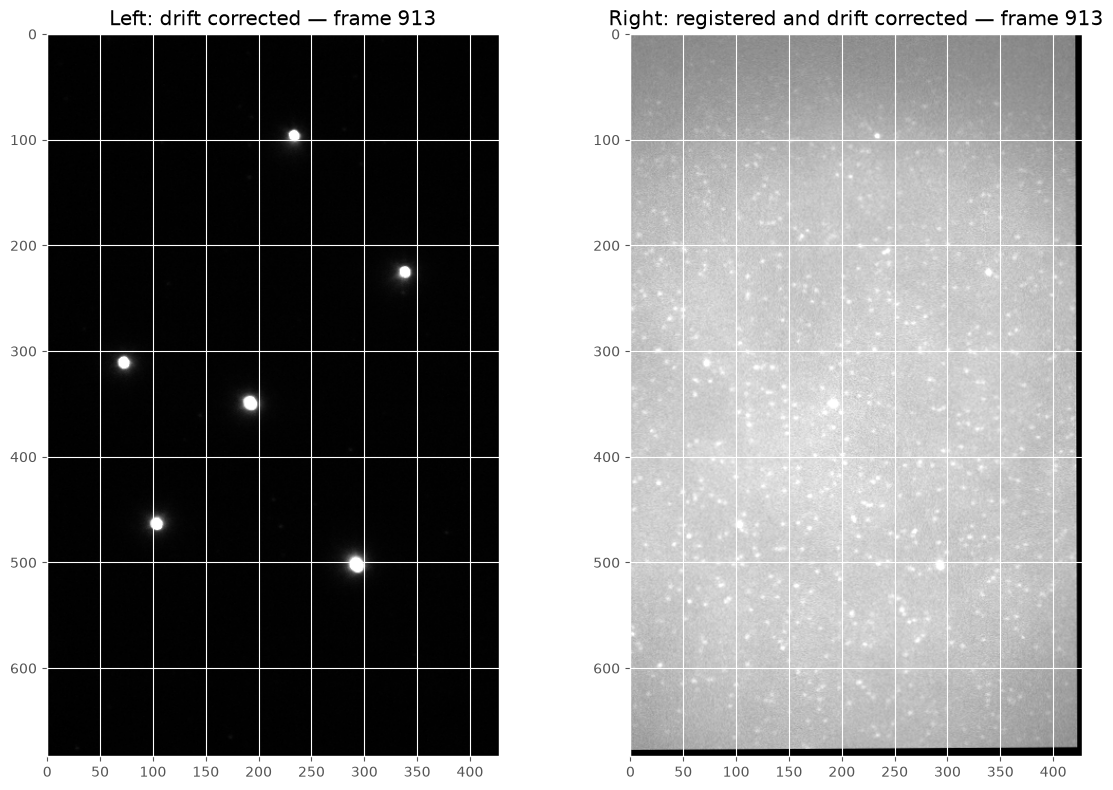

In [47]:
# RCC drift correction in the left channel's coordinate system.
# Run the localisation and homography cells above first. H maps right -> left.
import pandas as pd
from picasso.postprocess import undrift
from scipy.ndimage import shift as shift_image

# Use every 10th frame as a starting point; 1 uses every frame. Localisations
# retain the TIFF's real frame numbers, even when intermediate frames are skipped.
frame_stride = 10
# Approximate frames per RCC time segment (not a number of segments). Smaller
# values improve time resolution but leave fewer localisations in each segment.
segment_frames = 300

# Only one batch of sampled frames is held in memory at a time. The right
# frames need not be registered to estimate drift: the left is the reference.
localisation_batches = []
with Image.open(path) as movie:
    n_frames = movie.n_frames
    frame_width, frame_height = movie.size
    split_x = frame_width // 2
    sampled_frames = np.arange(0, n_frames, frame_stride)
    print(f"Localising {len(sampled_frames)} of {n_frames} frames...")
    for i, frame_index in enumerate(sampled_frames):
        movie.seek(int(frame_index))
        left_frame = np.asarray(movie)[:, :split_x].copy()
        locs = localize_frames(
            left_frame[np.newaxis, :, :],
            info=None,
            params=params.copy(),
            camera_info=camera_info.copy(),
            start_frame=int(frame_index),
            fitting_method="gausslq",
            threaded=False,
        )
        if not locs.empty:
            localisation_batches.append(locs)
        if (i + 1) % 25 == 0 or i + 1 == len(sampled_frames):
            print(f"  {i + 1}/{len(sampled_frames)} sampled frames")

if not localisation_batches:
    raise ValueError("No localisations found; inspect the detection parameters.")
left_locs_over_time = pd.concat(localisation_batches, ignore_index=True)

# Picasso 0.11.3 computes round(n_frames / segmentation) segments and fits a
# cubic spline to their shifts, requiring at least four segments.
n_segments = int(np.round(n_frames / segment_frames))
if n_segments < 4:
    raise ValueError("Choose a smaller segment_frames to obtain at least four segments.")
bounds = np.linspace(0, n_frames - 1, n_segments + 1, dtype=np.uint32)
counts = np.array([
    ((left_locs_over_time['frame'] >= bounds[i]) &
     (left_locs_over_time['frame'] < bounds[i + 1])).sum()
    for i in range(n_segments)
])
print("Localisations per RCC segment:", counts)
if np.any(counts == 0):
    raise ValueError("An RCC segment is empty. Sample more frames or adjust settings.")

# Picasso RCC, the same approach used by molSEEQ, but using the installed
# 0.11.3 DataFrame API. The values are relative drift in LEFT pixels.
info = [{"Frames": n_frames, "Height": frame_height, "Width": split_x,
         "Pixelsize": camera_info["Pixelsize"]}, {}]
drift, left_locs_undrifted = undrift(
    left_locs_over_time.copy(), info, segmentation=segment_frames, display=False
)
if len(drift) != n_frames or not np.isfinite(drift[["x", "y"]].to_numpy()).all():
    raise ValueError("Picasso returned invalid drift values; inspect localisations and RCC settings.")

# Set frame 0 as our explicit reference. Apply the same offset to Picasso's
# corrected coordinates so they remain consistent with these drift values.
origin = drift.loc[0, ["x", "y"]].copy()
drift.loc[:, ["x", "y"]] -= origin
left_locs_undrifted.loc[:, ["x", "y"]] += origin.to_numpy()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(drift.index, drift["x"], label="x drift")
ax.plot(drift.index, drift["y"], label="y drift")
ax.set(xlabel="Frame", ylabel="Drift relative to frame 0 (pixels)",
       title="Picasso RCC estimated drift")
ax.legend()
ax.grid(alpha=0.3)
plt.show()


def corrected_channels(frame_index):
    """Return one left and registered-right frame, corrected into frame-0 space.

    Images are read on demand; originals remain unchanged. Both outputs are
    float images; image warping and subpixel shifts interpolate pixel values.
    """
    if not 0 <= frame_index < n_frames:
        raise IndexError(f"Frame must be between 0 and {n_frames - 1}.")
    with Image.open(path) as movie:
        movie.seek(int(frame_index))
        raw = np.asarray(movie)
        left_raw = raw[:, :split_x].astype(np.float32)
        right_raw = raw[:, split_x:].astype(np.float32)

    # Right -> left coordinates, using the previously estimated homography.
    right_registered = cv2.warpPerspective(
        right_raw, H, (split_x, frame_height),
        flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0,
    )
    dx, dy = drift.loc[frame_index, ["x", "y"]].to_numpy(dtype=float)
    # molSEEQ applies (-dy, -dx) using scipy.ndimage.shift (default order=3).
    left_corrected = shift_image(left_raw, (-dy, -dx), mode="constant", cval=0.0)
    right_corrected = shift_image(right_registered, (-dy, -dx), mode="constant", cval=0.0)
    return left_corrected, right_corrected

# Inspect a corrected frame in both channels; call corrected_channels(t) for
# other frames. The correction is based on sampled LEFT localisations only.
preview_frame = n_frames // 2
left_corrected, right_corrected = corrected_channels(preview_frame)
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, img, title in zip(axes, (left_corrected, right_corrected),
                           ("Left: drift corrected", "Right: registered and drift corrected")):
    low, high = np.percentile(img, (1, 99.8))
    ax.imshow(img, cmap="gray", vmin=low, vmax=high)
    ax.set_title(f"{title} — frame {preview_frame}")
plt.tight_layout()
plt.show()

# The RCC model is a global x/y translation and assumes a sufficiently stable
# localisation pattern. Inspect the drift curve and compare fixed features at
# several times in both corrected channels before trusting the result.


In [ ]:
# Scrub through the corrected channels and compare their alignment.
# Run the drift correction cell above first. If needed, install widgets in
# this notebook kernel with: %pip install ipywidgets
import ipywidgets as widgets
from IPython.display import display

# Hold display limits fixed while scrubbing, so brightness changes are visible.
# The limits below only affect the display; they do not alter image data.
left_first, right_first = corrected_channels(0)
left_limits = np.percentile(left_first, [1, 99.8])
right_limits = np.percentile(right_first, [1, 99.8])

def display_scaled(image, limits):
    low, high = limits
    return np.clip((image - low) / max(float(high - low), 1e-12), 0, 1)

def show_corrected_frame(frame_index):
    left_image, right_image = corrected_channels(frame_index)
    left_display = display_scaled(left_image, left_limits)
    right_display = display_scaled(right_image, right_limits)

    # Overlay: left is green, registered right is magenta; coincident
    # features can look white. Limits differ between channels for visibility,
    # so overlay colours do not indicate equal raw intensities.
    overlay = np.stack((right_display, left_display, right_display), axis=-1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 8))
    axes[0].imshow(left_display, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Left: drift corrected")
    axes[1].imshow(right_display, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Right: registered + drift corrected")
    axes[2].imshow(overlay)
    axes[2].set_title("Overlay: left green / right magenta")
    for ax in axes:
        ax.set_xlabel("x (left-coordinate pixels)")
        ax.set_ylabel("y (left-coordinate pixels)")
    dx, dy = drift.loc[frame_index, ["x", "y"]]
    fig.suptitle(f"Frame {frame_index}  |  estimated drift: x={dx:.2f}, y={dy:.2f} px")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

frame_slider = widgets.IntSlider(
    value=0, min=0, max=n_frames - 1, step=1,
    description="Frame", continuous_update=False,
    layout=widgets.Layout(width="80%"),
)
# Updating only when the slider is released avoids rendering hundreds of frames
# while dragging. The number on the right can also be typed into directly.
viewer_output = widgets.interactive_output(show_corrected_frame, {"frame_index": frame_slider})
display(frame_slider, viewer_output)


Fitting calibration spots in frame 0…
Localising sampled frames: 16/183
Localising sampled frames: 32/183
Localising sampled frames: 48/183
Localising sampled frames: 64/183
Localising sampled frames: 80/183
Localising sampled frames: 96/183
Localising sampled frames: 112/183
Localising sampled frames: 128/183
Localising sampled frames: 144/183
Localising sampled frames: 160/183
Localising sampled frames: 176/183
Localising sampled frames: 183/183
Estimating RCC drift…


Correlating image pairs: 100%|██████████| 15/15 [00:00<00:00, 54.64pairs/s]


Writing corrected frames: 100/1826
Writing corrected frames: 200/1826
Writing corrected frames: 300/1826
Writing corrected frames: 400/1826
Writing corrected frames: 500/1826
Writing corrected frames: 600/1826
Writing corrected frames: 700/1826
Writing corrected frames: 800/1826
Writing corrected frames: 900/1826
Writing corrected frames: 1000/1826
Writing corrected frames: 1100/1826
Writing corrected frames: 1200/1826
Writing corrected frames: 1300/1826
Writing corrected frames: 1400/1826
Writing corrected frames: 1500/1826
Writing corrected frames: 1600/1826
Writing corrected frames: 1700/1826
Writing corrected frames: 1800/1826
Writing corrected frames: 1826/1826


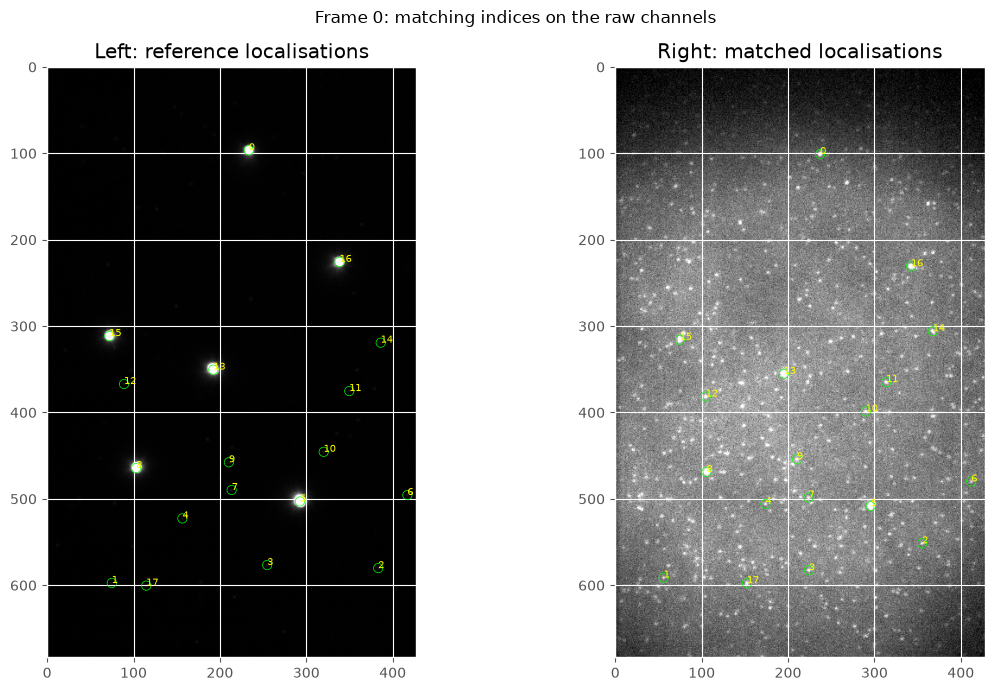

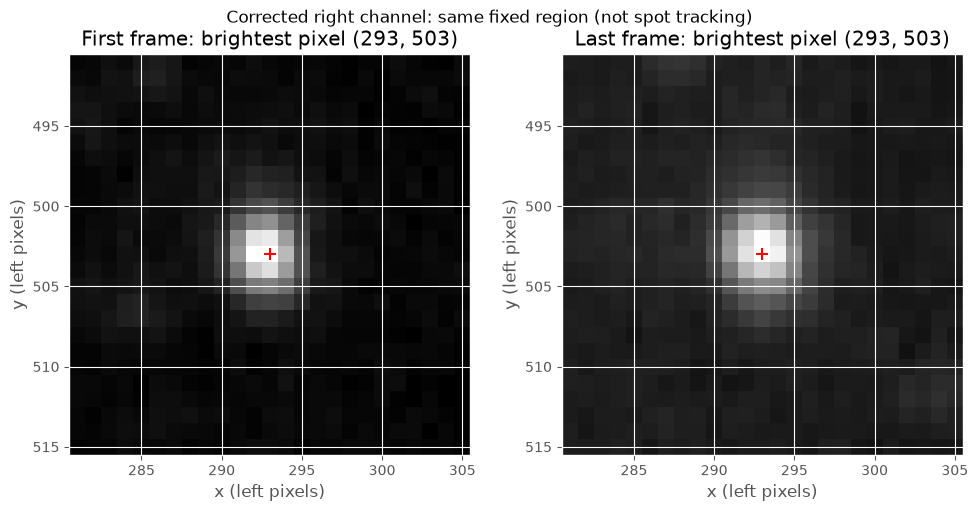

In [1]:
from preprocessing.preprocess_tif import preprocess_tif
import matplotlib.pyplot as plt

result = preprocess_tif(
    "low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif",
    "corrected.tif",
    plot_localisations=True,
    plot_drift=True,
)

plt.show()